#Meshal Mahnoor

# Lab Task 2



In [ ]:
#importing openCV  for task
import cv2
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
print("OpenCV:", cv2.__version__)

OpenCV: 4.14.0


In [ ]:
#importing libraries for conversion
from PIL import Image, ImageChops

**Task # 01:**

### Lab Task: Affine Transformation Order

Apply **scaling, rotation, and translation** to the given image using a single \(3\times3\) affine transformation matrix. Perform the transformations in the following three different orders:
- **Scaling → Rotation → Translation**
- **Rotation → Scaling → Translation**, and
- **Translation → Rotation → Scaling**.

Display the three resulting images side by side and compare them.

Observe whether changing the order of the transformations changes the final output. Based on your results, explain why the order of matrix multiplication affects the final transformed image.


Image shape: (547, 365, 3)
Height: 547
Width: 365
Channels: 3


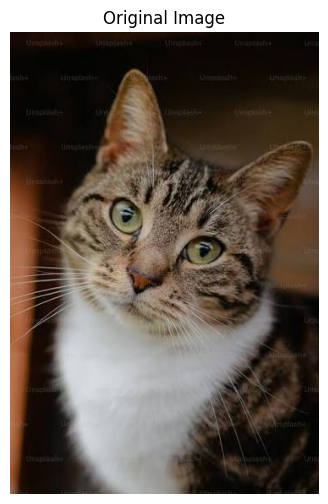

In [ ]:
#Converting the image to RGB and GrayScale:
# Change this path to your image
image_path = "cats.jpg"

# OpenCV loads images in BGR format
img = cv2.imread(image_path)

# if img is None:s
#  raise FileNotFoundError(f"Could not load image: {image_path}")

# Convert BGR -> RGB for matplotlib
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

print("Image shape:", img.shape)
print("Height:", img.shape[0])
print("Width:", img.shape[1])
print("Channels:", img.shape[2])

plt.figure(figsize=(8, 6))
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")
plt.show()

In [ ]:
#Order 1:
#Scaling > Rotation > Translation
#using the same points:
# Create a simple set of 2D points
points = np.array([
    [1, 1],
    [3, 1],
    [3, 3],
    [1, 3]
], dtype=float).T   # shape: (2, N)

print("Points:")
print(points.T)

Points:
[[1. 1.]
 [3. 1.]
 [3. 3.]
 [1. 3.]]


Original size: 365 × 547
Scaled up size: 548 × 820


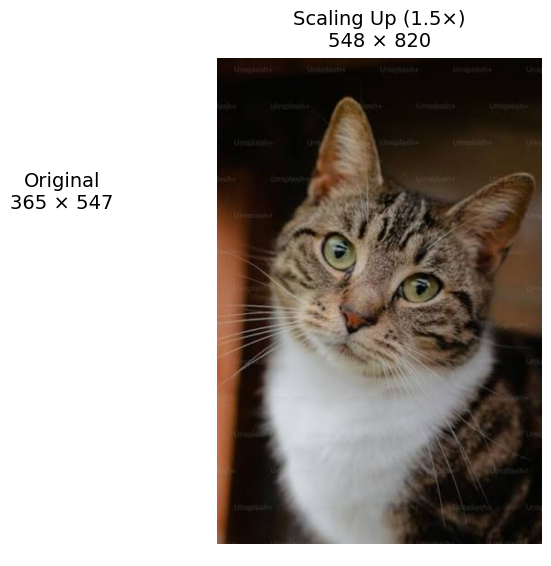

In [ ]:
#Scaling first:
# Scale up by 1.5×
scaled_up = cv2.resize(
    img_rgb,
    None,
    fx=1.5,
    fy=1.5,
    interpolation=cv2.INTER_LINEAR
)
h, w = img_rgb.shape[:2]
up_h, up_w = scaled_up.shape[:2]
print("Original size:", w, "×", h)
print("Scaled up size:", up_w, "×", up_h)

fig, ax = plt.subplots(figsize=(18, 7))

# Position of each image
x1 = 0
x2 = w + 80
x3 = x2 + up_w + 80

# Display images using their actual dimensions
ax.imshow(
    img_rgb,
    extent=[x1, x1 + w, 0, h]
)

ax.imshow(
    scaled_up,
    extent=[x2, x2 + up_w, 0, up_h]
)

# Titles
ax.text(
    x1 + w/2,
    h + 20,
    f"Original\n{w} × {h}",
    ha="center",
    fontsize=14
)

ax.text(
    x2 + up_w/2,
    up_h + 20,
    f"Scaling Up (1.5×)\n{up_w} × {up_h}",
    ha="center",
    fontsize=14
)

# Make sure the actual proportions are preserved
ax.set_aspect("equal")

# Remove axes
ax.axis("off")

# Set limits so all images are visible
ax.set_ylim(-20, up_h + 70)

plt.show()

Affine Transformation Matrix:
[[  0.866   0.5   -68.291]
 [ -0.5     0.866 241.93 ]]


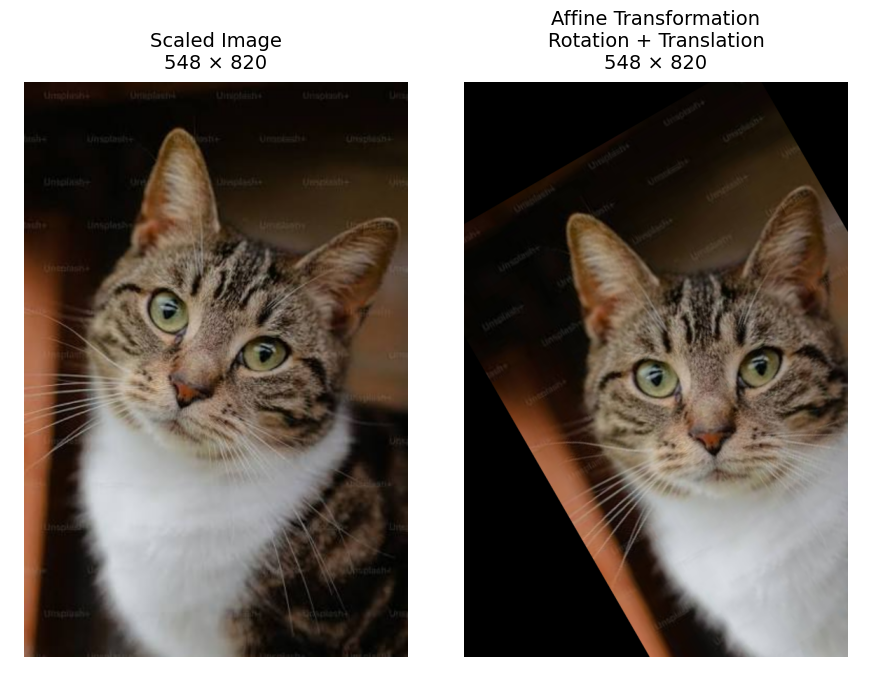

In [ ]:
#now rotating and translating
# Get image dimensions
h, w = scaled_up.shape[:2]

# ------------------------------------------------------------
# Define affine transformation
# ------------------------------------------------------------

# Rotation angle
angle = 30

# Scaling factor
scale = 1.0 # Since it is 1, so no scaling!

# Translation
tx = 100
ty = 50

# Create rotation + scaling matrix
M = cv2.getRotationMatrix2D(
    (w // 2, h // 2),
    angle,
    scale
)

# Add translation to the affine matrix
M[0, 2] += tx
M[1, 2] += ty

print("Affine Transformation Matrix:")
print(M)

# ------------------------------------------------------------
# Apply affine transformation
# ------------------------------------------------------------

transformed = cv2.warpAffine(
    scaled_up,
    M,
    (w, h)
)

# ============================================================
# DISPLAY WITH VISUAL CORRESPONDENCE TO ACTUAL SCALE
# ============================================================

# Get dimensions of both images (they match since output size was set to (w, h))
h_scaled, w_scaled = scaled_up.shape[:2]
h_trans, w_trans = transformed.shape[:2]

fig, ax = plt.subplots(figsize=(18, 7))

# Layout positioning variables for absolute visual spacing
x1 = 0
x2 = w_scaled + 80

# Display images using their actual physical boundaries in space
ax.imshow(
    scaled_up,
    extent=[x1, x1 + w_scaled, 0, h_scaled]
)

ax.imshow(
    transformed,
    extent=[x2, x2 + w_trans, 0, h_trans]
)

# Render Titles above each corresponding block
ax.text(
    x1 + w_scaled / 2,
    h_scaled + 20,
    f"Scaled Image\n{w_scaled} × {h_scaled}",
    ha="center",
    fontsize=14
)

ax.text(
    x2 + w_trans / 2,
    h_trans + 20,
    f"Affine Transformation\nRotation + Translation\n{w_trans} × {h_trans}",
    ha="center",
    fontsize=14
)

# Enforce uniform metric proportions across both dimensions
ax.set_aspect("equal")

# Strip baseline canvas axes decorations
ax.axis("off")

# Anchor dynamic bounding limit calculations for rendering safety margin
max_height = max(h_scaled, h_trans)
ax.set_ylim(-20, max_height + 90)
ax.set_xlim(-20, x2 + w_trans + 20)

plt.tight_layout()
plt.show()

Observation: The Image is scaled first and, the scaled image is than rotated and translated on that plane on which it is scaled.

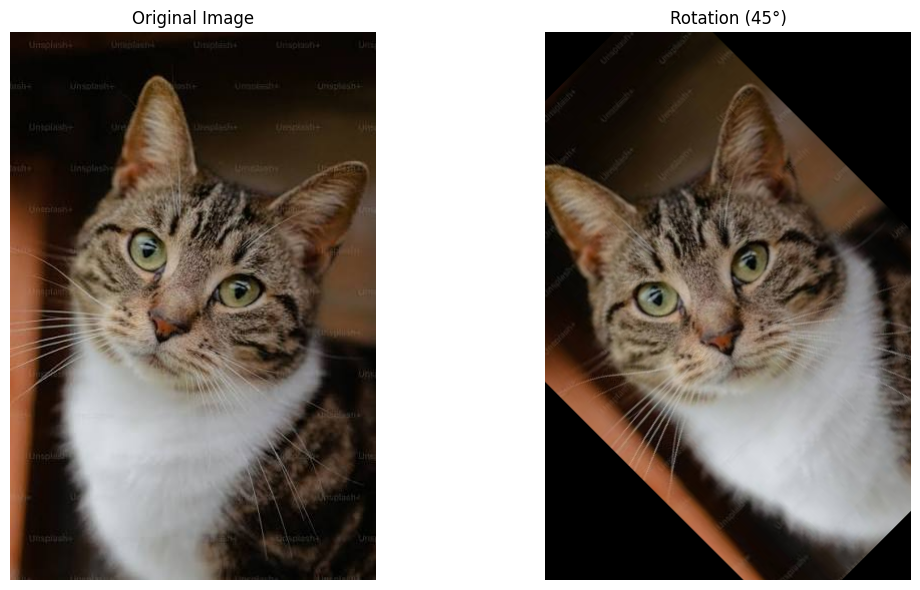

In [ ]:
#Order 2:
#Rotation > Scaling > Translation:
#Rotation of original image:
# ============================
# ROTATION
# ============================

# Get image dimensions
h, w = img_rgb.shape[:2]

# Rotation angle
angle = 45

# Rotation matrix
center = (w // 2, h // 2)

M = cv2.getRotationMatrix2D(
    center,
    angle,
    1.0
)

# Rotate the image
rotated = cv2.warpAffine(
    img_rgb,
    M,
    (w, h)
)

# ============================
# DISPLAY
# ============================

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(rotated)
plt.title("Rotation (45°)")
plt.axis("off")

plt.tight_layout()
plt.show()

Original size: 365 × 547
Scaled up size: 548 × 820


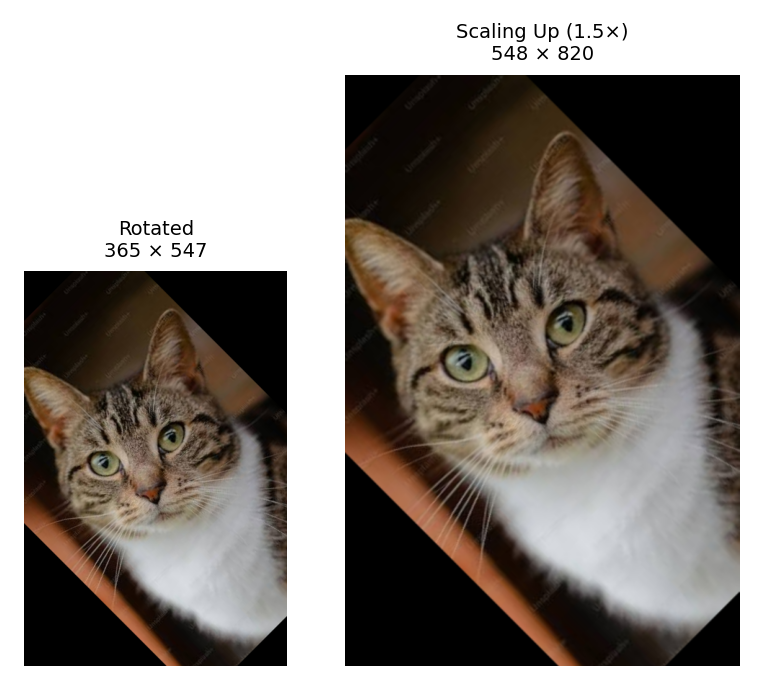

In [ ]:
scaled_up = cv2.resize(
    rotated,
    None,
    fx=1.5,
    fy=1.5,
    interpolation=cv2.INTER_LINEAR
)
h, w = rotated.shape[:2]
up_h, up_w = scaled_up.shape[:2]
print("Original size:", w, "×", h)
print("Scaled up size:", up_w, "×", up_h)

fig, ax = plt.subplots(figsize=(18, 7))

# Position of each image
x1 = 0
x2 = w + 80

# Display images using their actual dimensions
ax.imshow(
    rotated,
    extent=[x1, x1 + w, 0, h]
)

ax.imshow(
    scaled_up,
    extent=[x2, x2 + up_w, 0, up_h]
)

# Titles
ax.text(
    x1 + w/2,
    h + 20,
    f"Rotated\n{w} × {h}",
    ha="center",
    fontsize=14
)

ax.text(
    x2 + up_w/2,
    up_h + 20,
    f"Scaling Up (1.5×)\n{up_w} × {up_h}",
    ha="center",
    fontsize=14
)

# Make sure the actual proportions are preserved
ax.set_aspect("equal")

# Remove axes
ax.axis("off")

ax.set_ylim(-20, up_h + 90)
ax.set_xlim(-20, x2 + up_w + 20)

plt.tight_layout()
plt.show()

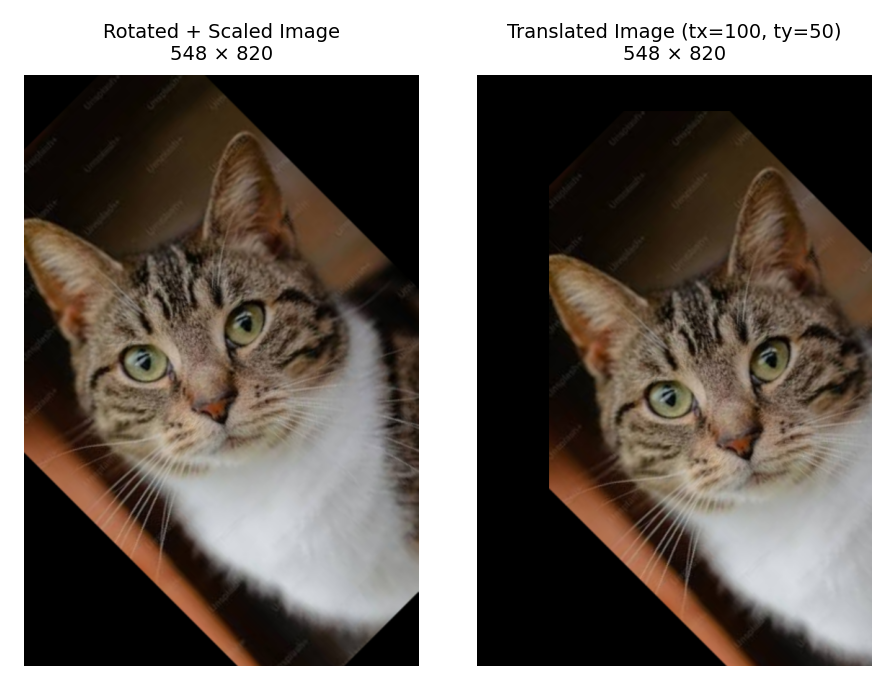

In [ ]:
#Finally translating:
# Get image dimensions
h, w = scaled_up.shape[:2]

tx = 100
ty = 50

# Create a pure translation affine matrix (2x3)
M_translation = np.array([
    [1, 0, tx],
    [0, 1, ty]
], dtype=np.float32)

# Apply translation
translated = cv2.warpAffine(
    scaled_up,
    M_translation,
    (w, h)
)

fig, ax = plt.subplots(figsize=(18, 7))

# Positions on the coordinate grid
x1 = 0
x2 = w + 80  # Spacing between images

# Display images using their actual canvas coordinates
ax.imshow(
    scaled_up,
    extent=[x1, x1 + w, 0, h]
)

ax.imshow(
    translated,
    extent=[x2, x2 + w, 0, h]
)

# Graph Titles
ax.text(
    x1 + w / 2,
    h + 20,
    f"Rotated + Scaled Image\n{w} × {h}",
    ha="center",
    fontsize=14
)

ax.text(
    x2 + w / 2,
    h + 20,
    f"Translated Image (tx={tx}, ty={ty})\n{w} × {h}",
    ha="center",
    fontsize=14
)

# Enforce equal physical proportions
ax.set_aspect("equal")

# Hide graph axes lines
ax.axis("off")

# Set strict limits so both images display at true size
ax.set_ylim(-20, h + 90)
ax.set_xlim(-20, x2 + w + 20)

plt.tight_layout()
plt.show()

The images are rotated first and on that same scale they are scaled up then tramsated in order, along the same plane.

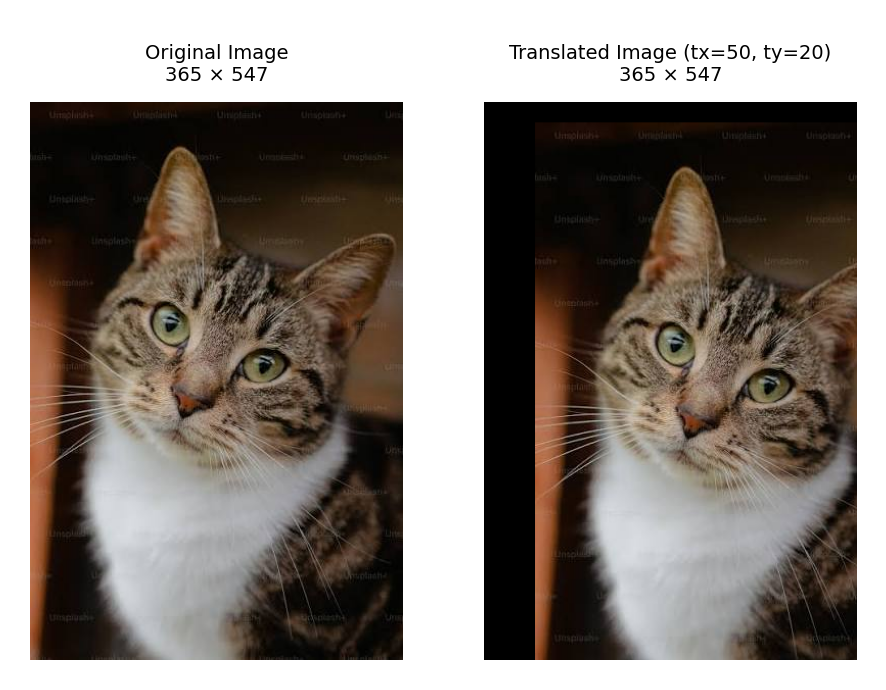

In [ ]:
#Order 3:
#Translation > Rotation > Scaling
#Translation:
h, w = img_rgb.shape[:2]

tx = 50
ty = 20

# Create a pure translation affine matrix (2x3)
M_translation = np.array([
    [1, 0, tx],
    [0, 1, ty]
], dtype=np.float32)

# Apply translation
translated = cv2.warpAffine(
    img_rgb,
    M_translation,
    (w, h)
)

fig, ax = plt.subplots(figsize=(18, 7))

# Positions on the coordinate grid
x1 = 0
x2 = w + 80  # Spacing between images

# Display images using their actual canvas coordinates
ax.imshow(
    img_rgb,
    extent=[x1, x1 + w, 0, h]
)

ax.imshow(
    translated,
    extent=[x2, x2 + w, 0, h]
)

# Graph Titles
ax.text(
    x1 + w / 2,
    h + 20,
    f"Original Image\n{w} × {h}",
    ha="center",
    fontsize=14
)

ax.text(
    x2 + w / 2,
    h + 20,
    f"Translated Image (tx={tx}, ty={ty})\n{w} × {h}",
    ha="center",
    fontsize=14
)

# Enforce equal physical proportions
ax.set_aspect("equal")

# Hide graph axes lines
ax.axis("off")

# Set strict limits so both images display at true size
ax.set_ylim(-20, h + 90)
ax.set_xlim(-20, x2 + w + 20)

plt.tight_layout()
plt.show()

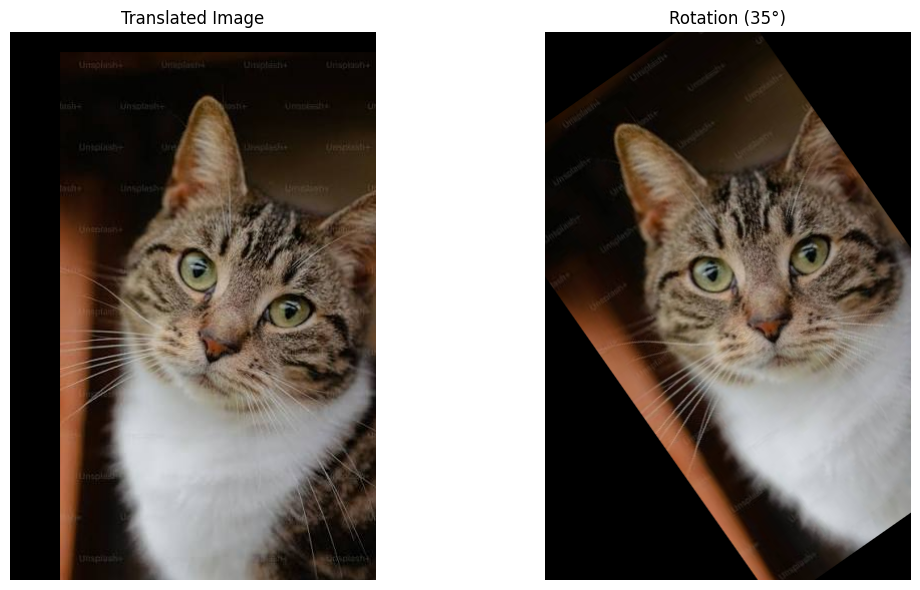

In [ ]:
#Rotation:
#Rotation of original image:
# ============================
# ROTATION
# ============================

# Get image dimensions
h, w = translated.shape[:2]

# Rotation angle
angle = 35

# Rotation matrix
center = (w // 2, h // 2)

M = cv2.getRotationMatrix2D(
    center,
    angle,
    1.0
)

# Rotate the image
rotated = cv2.warpAffine(
    translated,
    M,
    (w, h)
)

# ============================
# DISPLAY
# ============================

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(translated)
plt.title("Translated Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(rotated)
plt.title("Rotation (35°)")
plt.axis("off")

plt.tight_layout()
plt.show()

Rotated size: 365 × 547
Scaled down size: 219 × 328


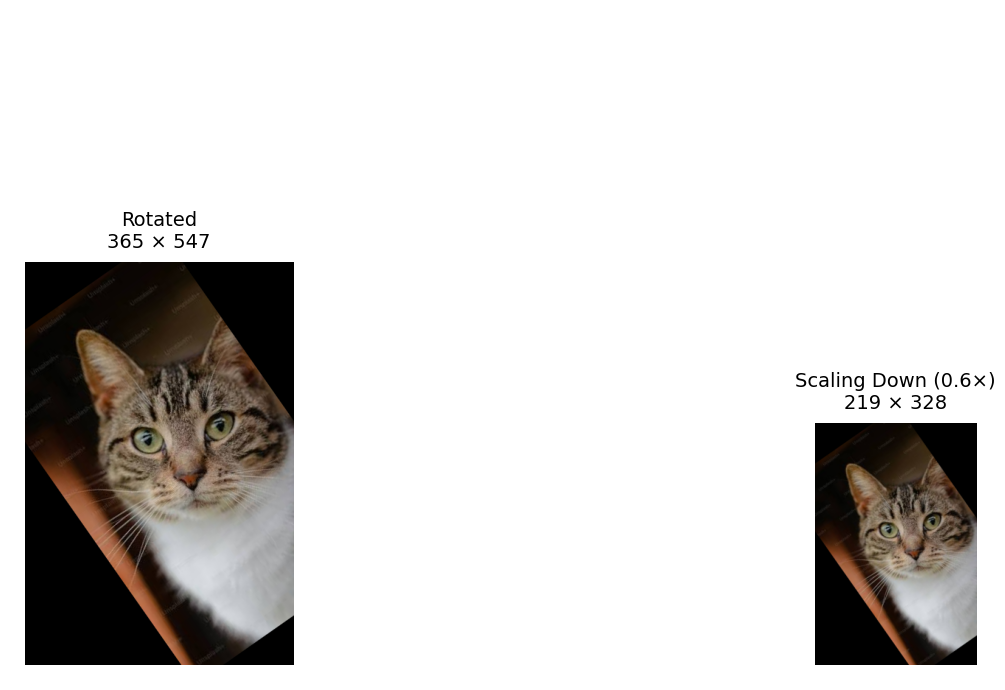

In [ ]:
#lastly we will scale this one down:
# Scale down by 0.6×
scaled_down = cv2.resize(
    rotated,
    None,
    fx=0.6,
    fy=0.6,
    interpolation=cv2.INTER_AREA
)
h, w = rotated.shape[:2]
down_h, down_w = scaled_down.shape[:2]

print("Rotated size:", w, "×", h)
print("Scaled down size:", down_w, "×", down_h)

fig, ax = plt.subplots(figsize=(18, 7))

# Position of each image
x1 = 0
x2 = w + 80
x3 = x2 + up_w + 80

# Display images using their actual dimensions
ax.imshow(
    rotated,
    extent=[x1, x1 + w, 0, h]
)

ax.imshow(
    scaled_down,
    extent=[x3, x3 + down_w, 0, down_h]
)

# Titles
ax.text(
    x1 + w/2,
    h + 20,
    f"Rotated\n{w} × {h}",
    ha="center",
    fontsize=14
)

ax.text(
    x3 + down_w/2,
    down_h + 20,
    f"Scaling Down (0.6×)\n{down_w} × {down_h}",
    ha="center",
    fontsize=14
)

# Make sure the actual proportions are preserved
ax.set_aspect("equal")

# Remove axes
ax.axis("off")

ax.set_xlim(-20, x3 + down_w + 20)
ax.set_ylim(-20, up_h + 70)


plt.tight_layout()
plt.show()

The image is first translated and, on that place, on those points from origin (0,0) to points (dx,dy), it is rotated and scaled about the new points (dx,dy)


**Task # 02:**

Apply image scaling using different interpolation techniques available in OpenCV. Scale the given image up by 2× and compare the results obtained using INTER_NEAREST, INTER_LINEAR, INTER_CUBIC, and INTER_LANCZOS4. Display the original image and all scaled versions together, then compare the images by observing differences in sharpness, smoothness, pixelation, and preservation of fine details. Also print the resulting image dimensions for each interpolation method and briefly state which interpolation method produces the most visually suitable result for upscaling and why.

Scaled up INTER_NEAREST:  730 × 1094
Scaled up INTER_LINEAR:    730 × 1094
Scaled up INTER_CUBIC:     730 × 1094
Scaled up INTER_LANCZOS4:  730 × 1094


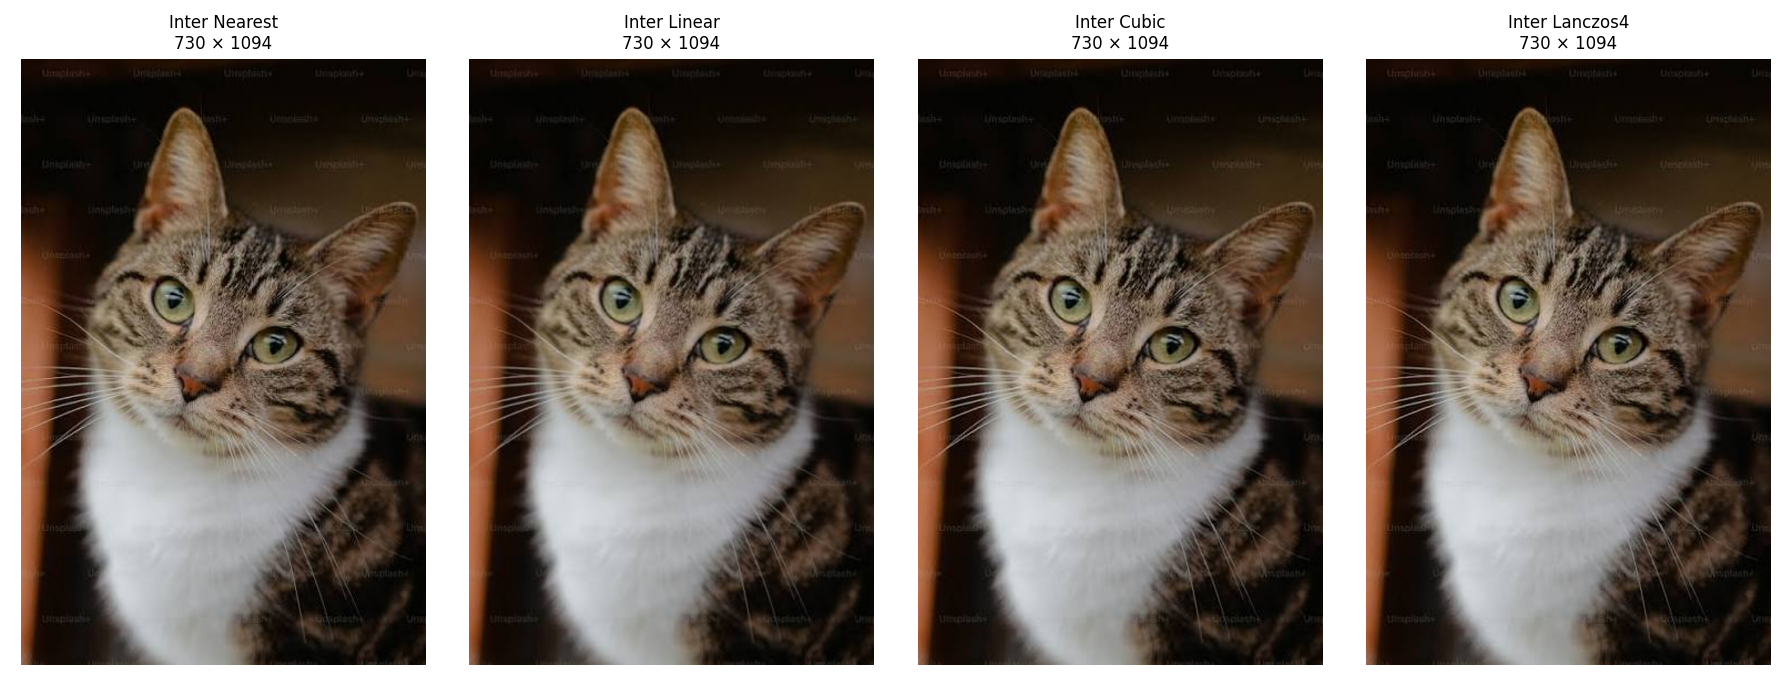

In [ ]:
#Comparing different scalings in an image:
# ============================
# SCALING
# ============================

# Scale up by 2 using different interpolations
scaled_up = cv2.resize(
    img_rgb,
    None,
    fx=2,
    fy=2,
    interpolation=cv2.INTER_NEAREST
)

scaled_up_2 = cv2.resize(
    img_rgb,
    None,
    fx=2,
    fy=2,
    interpolation=cv2.INTER_LINEAR
)

scaled_up_cubic = cv2.resize(
    img_rgb,
    None,
    fx=2,
    fy=2,
    interpolation=cv2.INTER_CUBIC
)

scaled_up_lanc = cv2.resize(
    img_rgb,
    None,
    fx=2,
    fy=2,
    interpolation=cv2.INTER_LANCZOS4
)

up_h, up_w = scaled_up.shape[:2]
up2_h, up2_w = scaled_up_2.shape[:2]
up3_h, up3_w = scaled_up_cubic.shape[:2]
up4_h, up4_w = scaled_up_lanc.shape[:2]

print("Scaled up INTER_NEAREST: ", up_w, "×", up_h)
print("Scaled up INTER_LINEAR:   ", up2_w, "×", up2_h)
print("Scaled up INTER_CUBIC:    ", up3_w, "×", up3_h)
print("Scaled up INTER_LANCZOS4: ", up4_w, "×", up4_h)

# Increased width of figure to fit all 4 images comfortably side-by-side
fig, ax = plt.subplots(figsize=(24, 7))

padding = 80
x1 = 0
x2 = x1 + up_w + padding
x3 = x2 + up2_w + padding
x4 = x3 + up3_w + padding

ax.imshow(
    scaled_up,
    extent=[x1, x1 + up_w, 0, up_h]
)

ax.imshow(
    scaled_up_2,
    extent=[x2, x2 + up2_w, 0, up2_h]
)

ax.imshow(
    scaled_up_cubic,
    extent=[x3, x3 + up3_w, 0, up3_h]
)

ax.imshow(
    scaled_up_lanc,
    extent=[x4, x4 + up4_w, 0, up4_h]
)

ax.text(
    x1 + up_w/2,
    up_h + 20,
    f"Inter Nearest\n{up_w} × {up_h}",
    ha="center",
    fontsize=12
)

ax.text(
    x2 + up2_w/2,
    up2_h + 20,
    f"Inter Linear\n{up2_w} × {up2_h}",
    ha="center",
    fontsize=12
)

ax.text(
    x3 + up3_w/2,
    up3_h + 20,
    f"Inter Cubic\n{up3_w} × {up3_h}",
    ha="center",
    fontsize=12
)

ax.text(
    x4 + up4_w/2,
    up4_h + 20,
    f"Inter Lanczos4\n{up4_w} × {up4_h}",
    ha="center",
    fontsize=12
)

# Make sure the actual proportions are preserved
ax.set_aspect("equal")

# Remove axes lines
ax.axis("off")

ax.set_xlim(-20, x4 + up4_w + 20)
ax.set_ylim(-20, up_h + 90)

plt.tight_layout()
plt.show()


Onservation:
In visual Observation,all interpolations do well in terms of scaling up the image, **inter nearest** will make it so that the nearest pixel is chosen, **inter linea**r checks the 2x2 pixels and makes a decision based on avg.
**Inter Cubic** makes its choice by taing a 4x4 grid and applying cubic polynomial formula.
**Inter Lanczos** will take an 8x8 nearest pixel grid and will apply a complex trignometric formula on it.

**Task # 03:**

Use any image and apply a homography transformation to change its perspective. Select four points from the image and map them to four new points to create a perspective-distorted or perspective-corrected image. Use cv2.getPerspectiveTransform() to calculate the homography matrix and cv2.warpPerspective() to apply it. Display the original and transformed images and observe how the perspective of the image changes.

In [ ]:
#creating destinatin points:
# Create a perspective-distorted quadrilateral from a rectangle.

src = np.float32([
    [120, 100],
    [520, 100],
    [520, 360],
    [120, 360]
])
dst = np.float32([
    [160, 80],
    [530, 130],
    [480, 390],
    [100, 350]
])
H = cv2.getPerspectiveTransform(src, dst)

print("Homography H:\n", H)

Homography H:
 [[  0.985  -0.24   66.552]
 [  0.139   1.015 -37.836]
 [  0.     -0.      1.   ]]


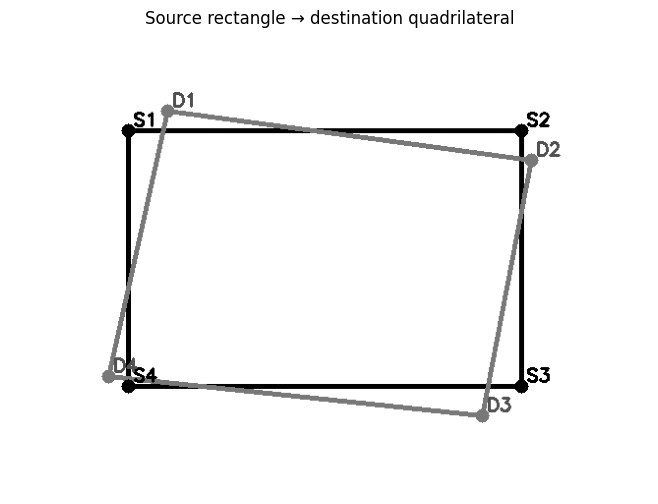

In [ ]:
# Draw the source and destination quadrilaterals for visualization.

canvas = np.ones((470, 650, 3), dtype=np.uint8) * 255

src_int = src.astype(int)
dst_int = dst.astype(int)

cv2.polylines(canvas, [src_int], True, (0, 0, 0), 3)
cv2.polylines(canvas, [dst_int], True, (120, 120, 120), 3)

for i, p in enumerate(src_int):
    cv2.circle(canvas, tuple(p), 7, (0, 0, 0), -1)
    cv2.putText(canvas, f"S{i+1}", tuple(p + [5, -5]),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 2)

for i, p in enumerate(dst_int):
    cv2.circle(canvas, tuple(p), 7, (120, 120, 120), -1)
    cv2.putText(canvas, f"D{i+1}", tuple(p + [5, -5]),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (80, 80, 80), 2)

plt.figure(figsize=(9, 6))
plt.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Source rectangle → destination quadrilateral")
plt.show()

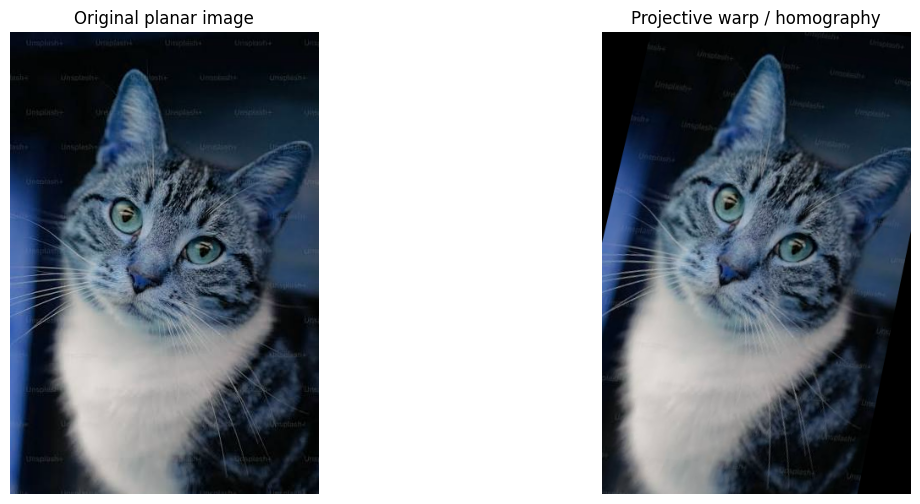

In [ ]:
# Apply the homography to the synthetic image.
homography_img = cv2.warpPerspective(img_rgb, H, (w, h))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(cv2.cvtColor(img_rgb, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original planar image")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(homography_img, cv2.COLOR_BGR2RGB))
axes[1].set_title("Projective warp / homography")
axes[1].axis("off")

plt.show()